In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from google.colab import  files

In [2]:
os.makedirs('images', exist_ok=True)

print("Please Upload The Required Images:")
print("- Book1")
print("- Book2")

uploaded = files.upload()

for filename in uploaded.keys():
  dest = os.path.join('images', filename)
  os.rename(filename, dest)
  print(f"Uploaded: {filename}")

print("\nContents Of Images Folder:")
print(os.listdir('images'))

Please Upload The Required Images:
- Book1
- Book2


Saving Book1.jpg to Book1.jpg
Saving Book2.jpg to Book2.jpg
Uploaded: Book1.jpg
Uploaded: Book2.jpg

Contents Of Images Folder:
['Book1.jpg', 'Book2.jpg']


In [3]:
img1 = cv2.imread('images/Book1.jpg')
img2 = cv2.imread('images/Book2.jpg')

original_img1 = cv2.imread('images/Book1.jpg')
original_img2 = cv2.imread('images/Book2.jpg')
result = original_img2.copy()

sift = cv2.SIFT_create()

keypoints_1, descriptors_1 = sift.detectAndCompute(img1, None)
keypoints_2, descriptors_2 = sift.detectAndCompute(img2, None)

In [5]:
FLANN_INDEX_KDTREE = 0
index_params = dict(algorithm=FLANN_INDEX_KDTREE, trees=5)
search_params = dict(checks=50)

flann = cv2.FlannBasedMatcher(index_params, search_params)
matches = flann.knnMatch(descriptors_1, descriptors_2, k=2)

good_matches = []
for m, n in matches:
  if m.distance < 0.7 * n.distance:
    good_matches.append(m)

In [16]:
MIN_MATCH_COUNT = 10

if len(good_matches) > MIN_MATCH_COUNT:
  scr_pts = np.float32([keypoints_1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
  dst_pts = np.float32([keypoints_2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
  M, mask = cv2.findHomography(scr_pts, dst_pts, cv2.RANSAC, 5.0)
  matches_mask = mask.ravel().tolist()
  h, w = img1.shape[:2]
  pts = np.float32([[0, 0], [0, h-1], [w-1, h-1], [w-1, 0]]).reshape(-1, 1, 2)
  dst = cv2.perspectiveTransform(pts, M)
  result = cv2.polylines(result, [np.int32(dst)], True, (255, 0, 0), 3, cv2.LINE_AA)

  print("Homography Matrix M:")
  print(M)
else:
  print(f"Not Enough Matches Are Found - {len(good_matches)}/{MIN_MATCH_COUNT}")
  matchesMask = None

Homography Matrix M:
[[ 1.75749209e+00  1.47445330e+00 -7.40999818e+02]
 [-7.66854948e-01  2.04573751e+00 -9.89702652e+01]
 [ 5.86929817e-04  6.64701045e-04  1.00000000e+00]]


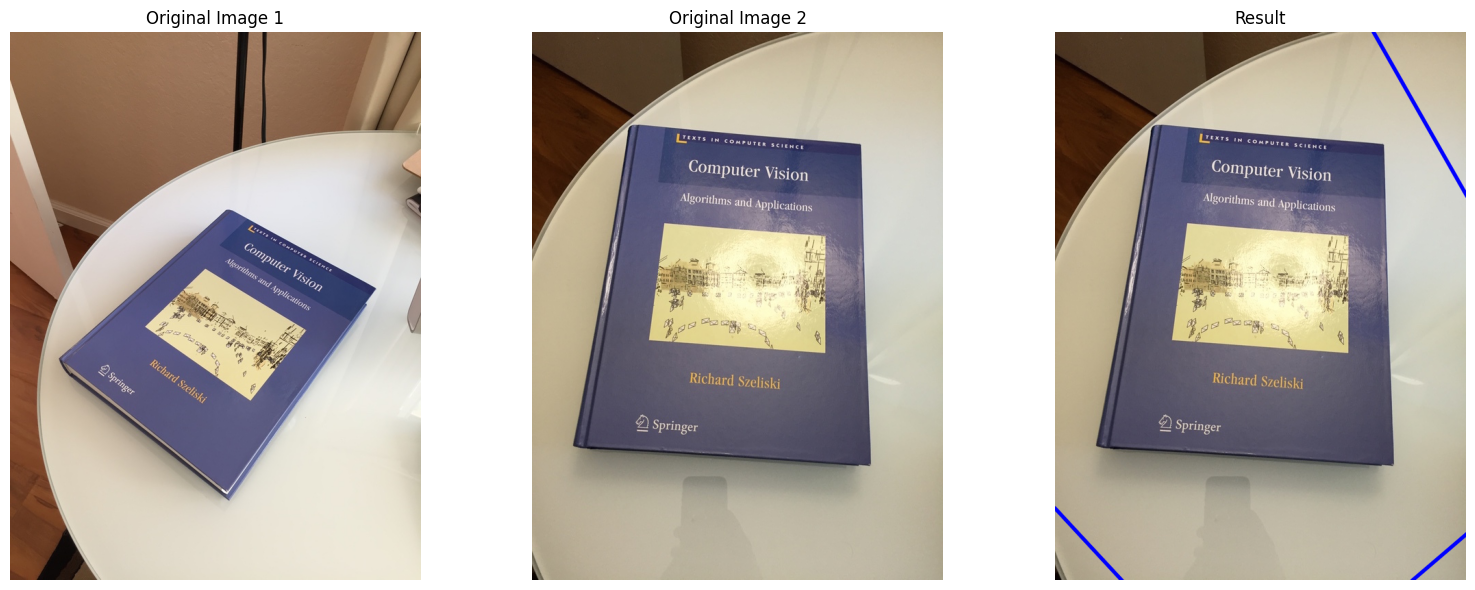

In [14]:
plt.figure(figsize=(16, 6))

plt.subplot(1, 3, 1)
plt.imshow(original_img1[..., ::-1])
plt.title('Original Image 1')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(original_img2[..., ::-1])
plt.title('Original Image 2')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(result[..., ::-1])
plt.title('Result')
plt.axis('off')

plt.tight_layout()
plt.show()

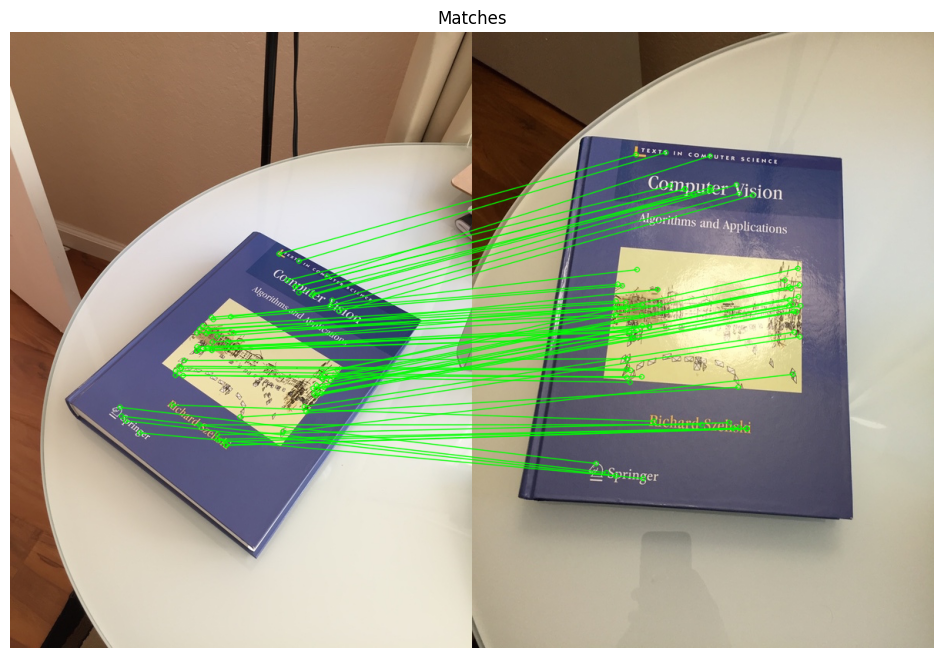

In [15]:
draw_params = dict(matchColor=(0, 255, 0), singlePointColor=None, flags=2, matchesMask=matches_mask)
img_matches = cv2.drawMatches(img1, keypoints_1, img2, keypoints_2, good_matches, None, **draw_params)

plt.figure(figsize=(16, 8))

plt.imshow(img_matches[..., ::-1])
plt.title('Matches')
plt.axis('off')

plt.show()